# NBA Draft Value Analysis (2000–2020)
### Who Were the Biggest Steals and Busts?

This notebook analyzes **21 years of NBA draft data** to answer:
- What career value does each draft position *typically* produce?
- Which players massively **outperformed** their draft slot (steals)?
- Which high picks **underperformed** expectations (busts)?
- Which **teams** are the best and worst drafters?
- Can we **predict** career value from draft position?

**Data:** Basketball Reference (scraped)  
**Value metric:** Composite of Win Shares + VORP  
**Models:** Polynomial regression (baseline), Gradient Boosting (improved)

## 0. Setup

In [1]:
import sys, os

# In Google Colab, download the project code first (the notebook alone doesn't include it)
if 'google.colab' in sys.modules and not os.path.exists('../src'):
    !git clone -q https://github.com/Agastya191/nba-draft-analysis.git /content/nba-draft-analysis
    %cd /content/nba-draft-analysis/notebooks

sys.path.insert(0, os.path.abspath('../src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import warnings
warnings.filterwarnings('ignore')

from scraper    import scrape_all_drafts
from preprocess import clean_and_engineer
from analysis   import run_all_analyses
from model      import run_models
from visualize  import generate_all_figures, set_style

set_style()
print('Setup complete.')

Setup complete.


## 1. Load Data

The repo includes a snapshot of the scraped data (`data/draft_data_raw.csv`), so this loads instantly.
If you delete that file, this cell re-scrapes Basketball Reference (about 2 minutes, 4 seconds between requests). Basketball Reference blocks cloud servers like Colab, so re-scraping only works on your own computer.

In [2]:
RAW_PATH = '../data/draft_data_raw.csv'

# Use the cached file only if it has the Win Shares column (older caches don't)
cached = pd.read_csv(RAW_PATH) if os.path.exists(RAW_PATH) else None
if cached is not None and 'win_shares' in cached.columns:
    print('Loading cached data...')
    raw_df = cached
    print(f'Loaded {len(raw_df)} picks from cache.')
else:
    print('Scraping data from Basketball Reference...')
    raw_df = scrape_all_drafts(start=2000, end=2020, save_path=RAW_PATH)

raw_df.head()

Loading cached data...
Loaded 1249 picks from cache.


,pick,player,team,college,draft_year,years_active,games,minutes,win_shares,ws_per_48,BPM,VORP
0,1,Kenyon Martin,NJN,Cincinnati,2000,15.0,757.0,23134.0,48.0,0.100,0.1,12.1
1,2,Stromile Swift,VAN,LSU,2000,9.0,547.0,10804.0,21.3,0.095,-1.6,1.1
2,3,Darius Miles,LAC,NaN,2000,7.0,446.0,11730.0,9.5,0.039,-1.0,3.0
3,4,Marcus Fizer,CHI,Iowa State,2000,6.0,289.0,6032.0,2.7,0.022,-3.7,-2.5
4,5,Mike Miller,ORL,Florida,2000,17.0,1032.0,27812.0,60.7,0.105,0.8,19.8


## 2. Clean & Engineer Features

In [3]:
df = clean_and_engineer(raw_df)
print(f'\nDataset: {len(df)} picks across {df["draft_year"].nunique()} draft years')
df[['player','draft_year','pick','pick_tier','win_shares','VORP','value_score','value_over_expected']].head(10)

Processed 1249 draft picks.
  Steals: 125 | Busts: 125

Dataset: 1249 picks across 21 draft years


,player,draft_year,pick,pick_tier,win_shares,VORP,value_score,value_over_expected
0,Kenyon Martin,2000,1,Top 5,48.0,12.1,43.32,0.00
1,Stromile Swift,2000,2,Top 5,21.3,1.1,14.10,0.00
2,Darius Miles,2000,3,Top 5,9.5,3.0,9.30,-43.62
3,Marcus Fizer,2000,4,Top 5,2.7,-2.5,-1.38,-26.28
4,Mike Miller,2000,5,Top 5,60.7,19.8,60.18,21.00
5,DerMarr Johnson,2000,6,Lottery (6-10),6.4,0.6,4.56,-14.70
6,Chris Mihm,2000,7,Lottery (6-10),13.3,-4.2,2.94,-24.30
7,Jamal Crawford,2000,8,Lottery (6-10),60.7,18.3,58.38,42.72
8,Joel Przybilla,2000,9,Lottery (6-10),23.0,0.9,14.88,0.00
9,Keyon Dooling,2000,10,Lottery (6-10),18.5,-0.2,10.86,-1.44


In [4]:
# Distribution of value scores
print('Value Score Distribution:')
df['value_score'].describe().round(2)

Value Score Distribution:


count    1249.00
mean       15.11
std        29.06
min        -4.74
25%         0.00
50%         1.92
75%        18.66
max       356.58
Name: value_score, dtype: float64

## 3. Run All Analyses

In [5]:
results       = run_all_analyses(df)
model_results = run_models(df)

Running analyses...
  All analyses complete.
Training models...


  Baseline model  — CV MAE: 15.54 WS | R²: 0.195
  Improved model  — CV MAE: 16.0 value pts | R²: 0.12
  Team efficiency — 30 teams ranked


## 4. Draft Value Curve

In [6]:
print('Pick Value Curve (median WS by pick):')
results['pick_value_curve'].head(15)

Pick Value Curve (median WS by pick):


,pick,median_ws,median_value,n
0,1,44.5,43.32,21
1,2,21.0,14.10,21
2,3,58.4,52.92,21
3,4,29.9,24.90,21
4,5,41.7,39.18,21
5,6,24.6,19.26,21
6,7,34.6,27.24,21
7,8,18.3,15.66,21
8,9,23.0,14.88,21
9,10,15.3,12.30,21


In [7]:
print(f'Baseline model (pick → WS): MAE={model_results["baseline"]["cv_mae"]} WS, R²={model_results["baseline"]["cv_r2"]}')
print(f'Improved model (pick+era → value): MAE={model_results["improved"]["cv_mae"]}, R²={model_results["improved"]["cv_r2"]}')
print(f'\nFeature Importances:')
print(model_results['improved']['feature_importance'])

Baseline model (pick → WS): MAE=15.54 WS, R²=0.195
Improved model (pick+era → value): MAE=16.0, R²=0.12

Feature Importances:
pick          0.529906
draft_year    0.454581
round         0.015513
dtype: float64


## 5. Greatest Steals

In [8]:
print('TOP 20 DRAFT STEALS (2000-2020)')
print('Players who most outperformed their draft position expected value')
print('='*70)
results['top_steals'][['player','draft_year','pick','win_shares','VORP','value_over_expected']]

TOP 20 DRAFT STEALS (2000-2020)
Players who most outperformed their draft position expected value


,player,draft_year,pick,win_shares,VORP,value_over_expected
0,LeBron James,2003,1,277.3,158.5,313.26
1,Chris Paul,2005,4,215.2,98.0,221.82
2,Kevin Durant,2007,2,187.5,92.2,209.04
3,Nikola Jokić,2014,41,144.5,83.0,186.30
4,James Harden,2009,3,183.2,87.4,161.88
5,Stephen Curry,2009,7,149.1,77.9,155.70
6,Giannis Antetokounmpo,2013,15,127.2,66.0,149.64
7,Jimmy Butler,2011,30,129.4,52.5,136.68
8,Kawhi Leonard,2011,15,112.0,55.0,127.32
9,Damian Lillard,2012,6,119.6,54.7,118.14


## 6. Biggest Busts

In [9]:
print('TOP 20 DRAFT BUSTS (2000-2020, Picks 1-20 only)')
print('High picks who most underperformed their expected value')
print('='*70)
results['top_busts'][['player','draft_year','pick','win_shares','VORP','value_over_expected']]

TOP 20 DRAFT BUSTS (2000-2020, Picks 1-20 only)
High picks who most underperformed their expected value


,player,draft_year,pick,win_shares,VORP,value_over_expected
0,Adam Morrison,2006,3,-1.4,-2.4,-56.64
1,Jahlil Okafor,2015,3,7.2,0.0,-48.60
2,Anthony Bennett,2013,1,0.5,-1.3,-44.58
3,Darius Miles,2000,3,9.5,3.0,-43.62
4,Nikoloz Tskitishvili,2002,5,-1.6,-2.0,-42.54
5,RJ Barrett,2019,3,18.1,2.0,-39.66
6,Mario Hezonja,2015,5,3.4,-1.2,-38.58
7,Thomas Robinson,2012,5,4.6,-1.5,-38.22
8,Greg Oden,2007,1,7.3,0.8,-37.98
9,Markelle Fultz,2017,1,8.3,1.1,-37.02


## 7. Best Second-Round Picks

In [10]:
print('BEST SECOND ROUND PICKS (2000-2020)')
results['second_round_steals'][['player','draft_year','pick','win_shares','VORP']]

BEST SECOND ROUND PICKS (2000-2020)


,player,draft_year,pick,win_shares,VORP
0,Nikola Jokić,2014,41,144.5,83.0
1,DeAndre Jordan,2008,35,99.6,22.3
2,Paul Millsap,2006,47,95.4,29.8
3,Marc Gasol,2007,48,85.3,36.4
4,Carlos Boozer,2002,35,80.3,23.0
5,Kyle Korver,2003,51,73.4,20.6
6,Draymond Green,2012,35,66.6,28.0
7,Lou Williams,2005,45,65.7,23.0
8,Trevor Ariza,2004,43,64.3,21.8
9,Marcin Gortat,2005,57,61.3,12.7


## 8. Value by Pick Tier

In [11]:
results['value_by_tier'].style \
    .background_gradient(cmap='Blues', subset=['median_ws']) \
    .background_gradient(cmap='Reds',  subset=['pct_busts'])

,pick_tier,n_picks,median_ws,median_vorp,median_value,pct_busts,pct_steals
0,Top 5,105,35.400000,10.300000,32.640000,35.200000,21.000000
1,Lottery (6-10),105,23.000000,3.700000,17.640000,30.500000,19.000000
2,Lottery (11-14),84,18.450000,2.150000,12.870000,22.600000,13.100000
3,Late 1st,334,10.250000,0.200000,6.060000,11.100000,11.700000
4,Early 2nd,315,1.100000,0.000000,0.240000,0.000000,7.300000
5,Late 2nd,306,0.000000,0.000000,0.000000,0.000000,3.300000


## 9. Team Drafting Efficiency

In [12]:
print('BEST DRAFTING TEAMS (min 10 picks, 2000-2020)')
model_results['teams'][['team','total_picks','avg_value_over_exp','total_value_over_exp','best_pick']].head(15)

BEST DRAFTING TEAMS (min 10 picks, 2000-2020)


,team,total_picks,avg_value_over_exp,total_value_over_exp,best_pick
0,OKC,49,14.57,713.88,Kevin Durant
1,NOP,33,14.39,474.90,Chris Paul
2,DEN,36,13.88,499.74,Nikola Jokić
3,HOU,34,13.72,466.38,Nicolas Batum
4,CLE,35,13.65,477.84,LeBron James
5,GSW,36,12.23,440.40,Stephen Curry
6,TOR,32,11.28,360.90,DeMar DeRozan
7,SAS,45,11.14,501.24,Tony Parker
8,IND,35,10.90,381.48,Kawhi Leonard
9,MEM,35,10.35,362.28,Kyle Lowry


## 10. Generate All Figures

Generating figures...


  Saved: outputs/01_pick_value_curve.png


  Saved: outputs/02_top_steals.png


  Saved: outputs/03_top_busts.png


  Saved: outputs/04_value_by_tier.png
  Saved: outputs/06_second_round_steals.png


  Saved: outputs/07_era_comparison.png
  Saved: outputs/05_team_efficiency.png
  7 figures saved.


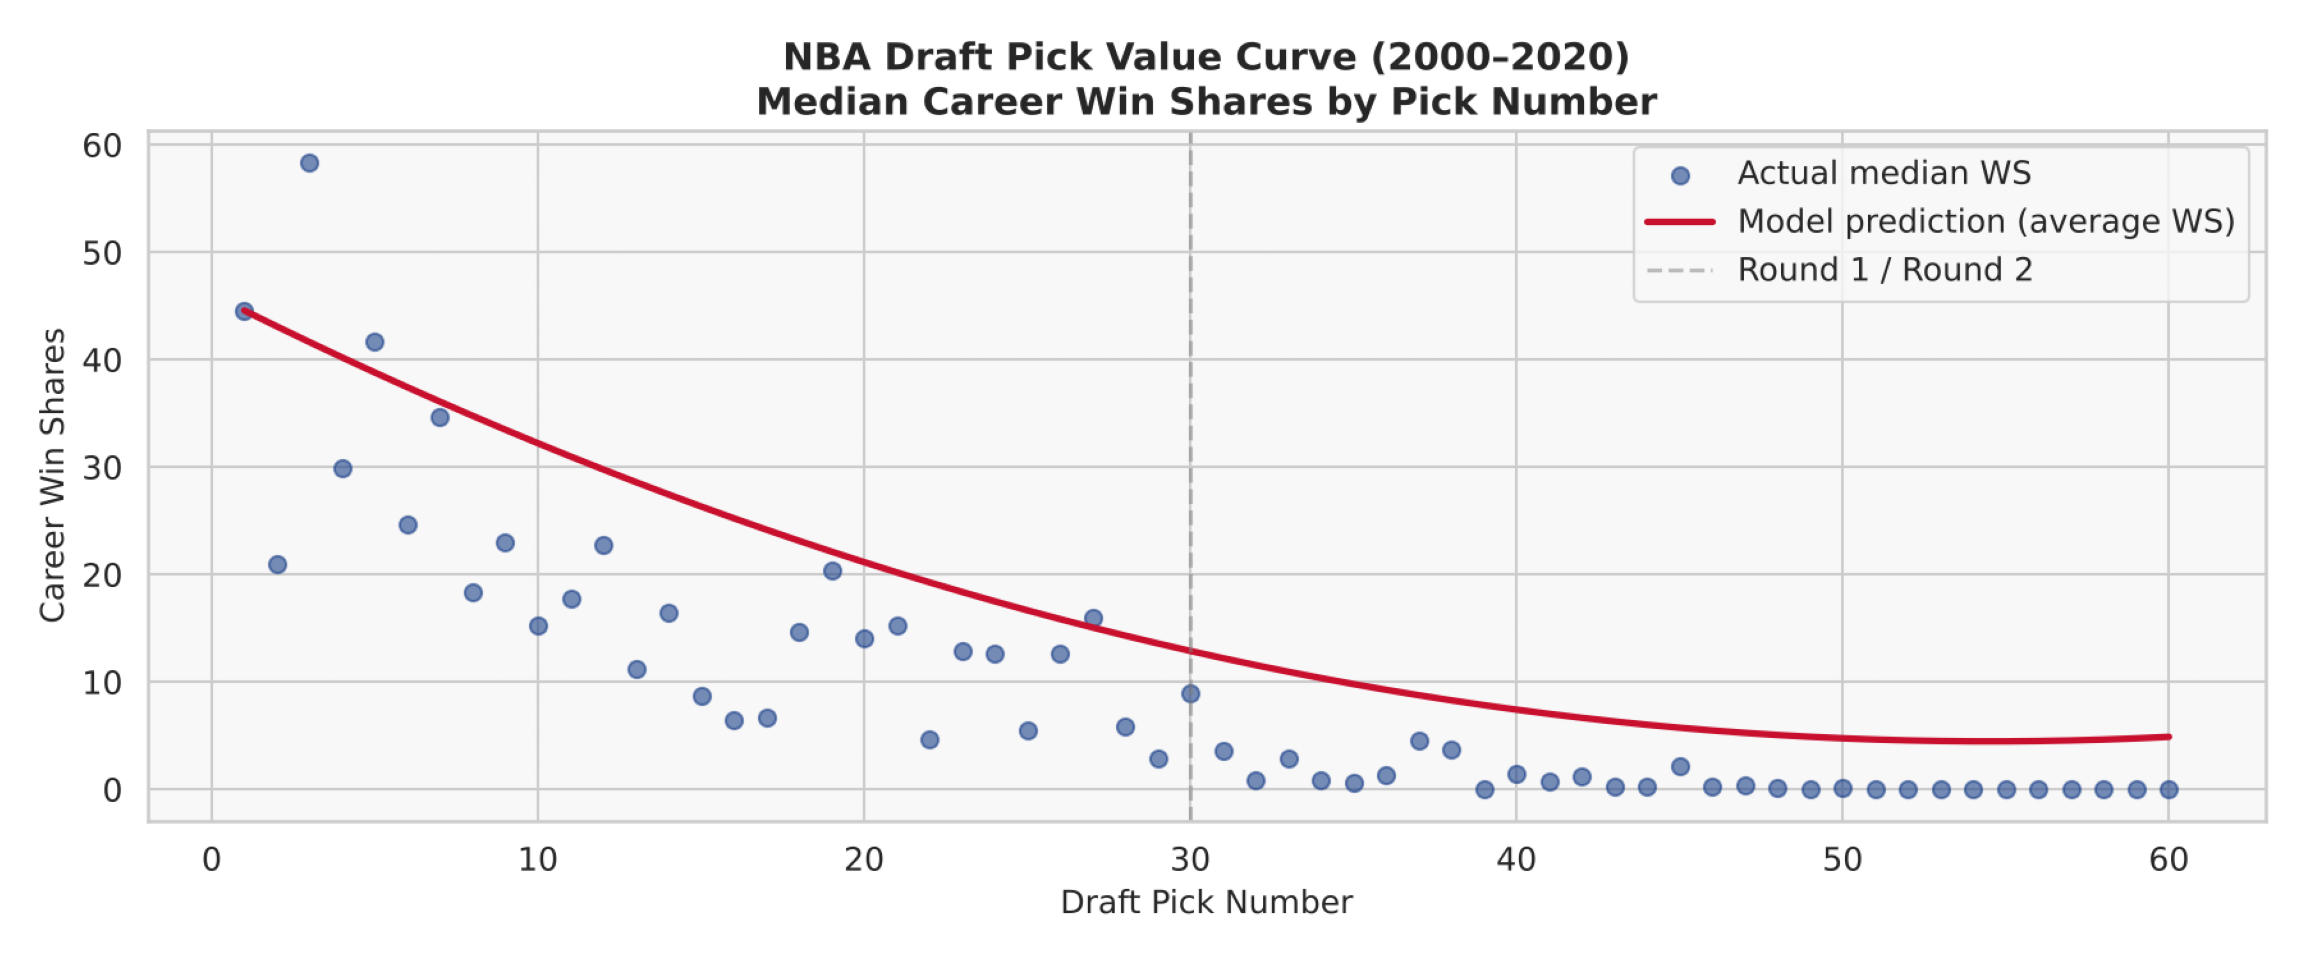

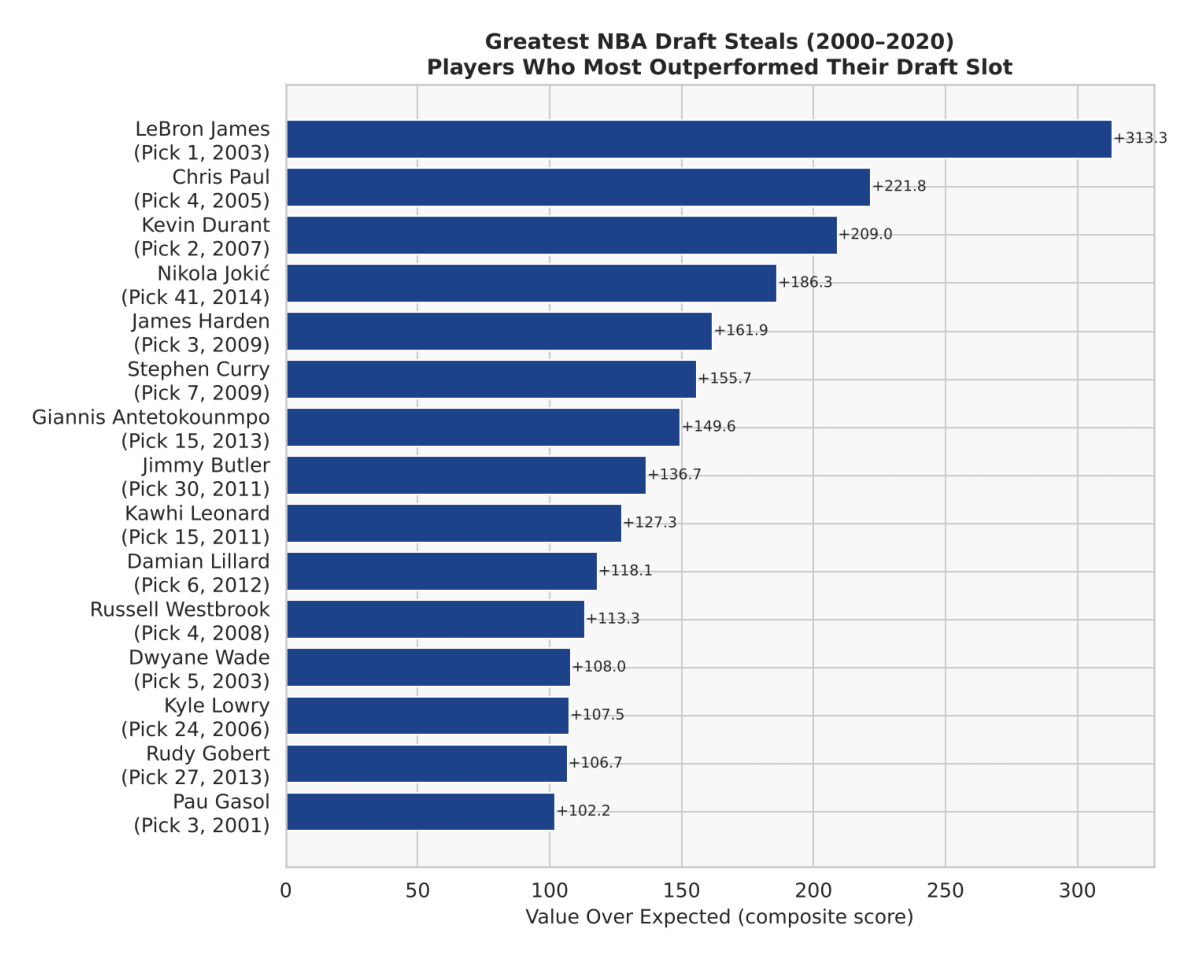

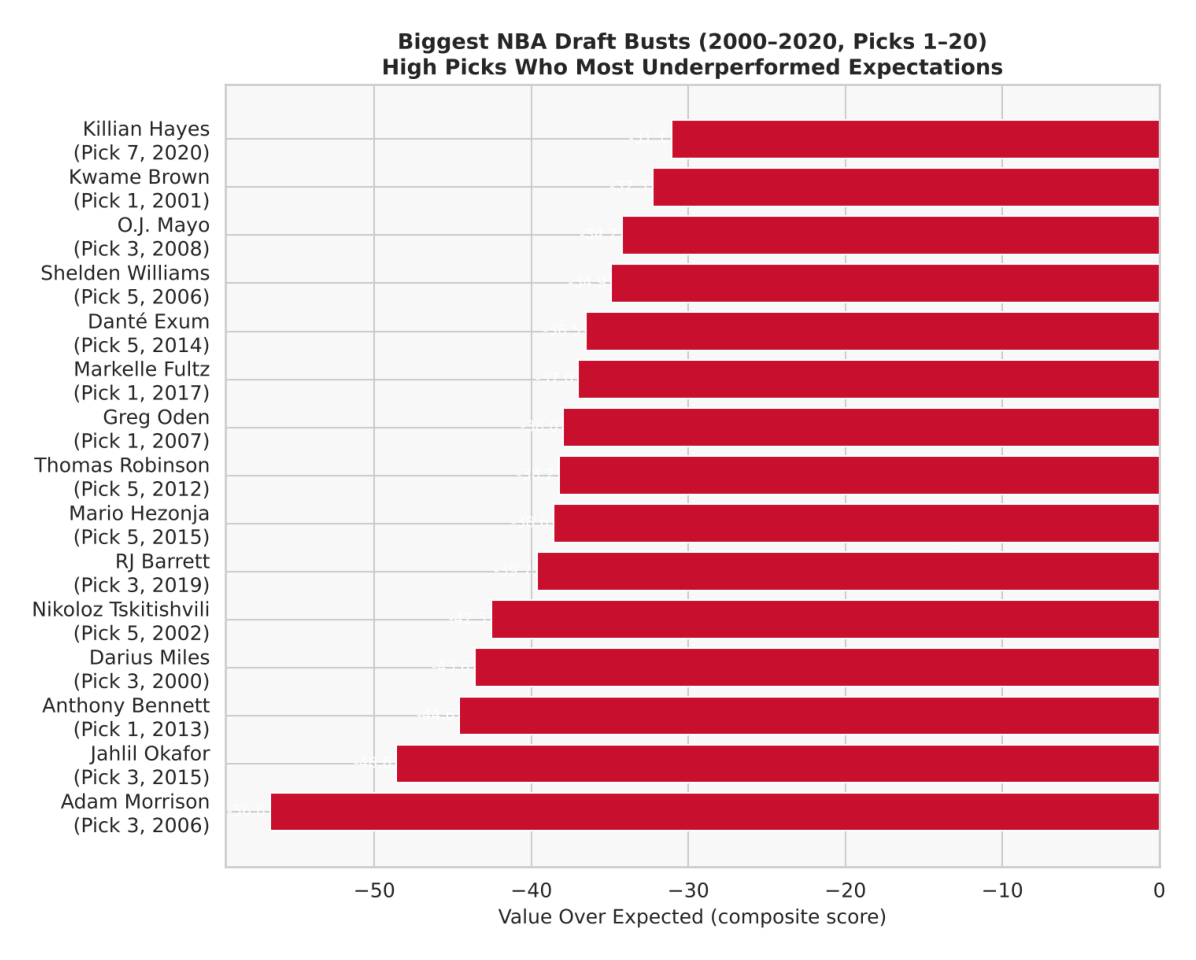

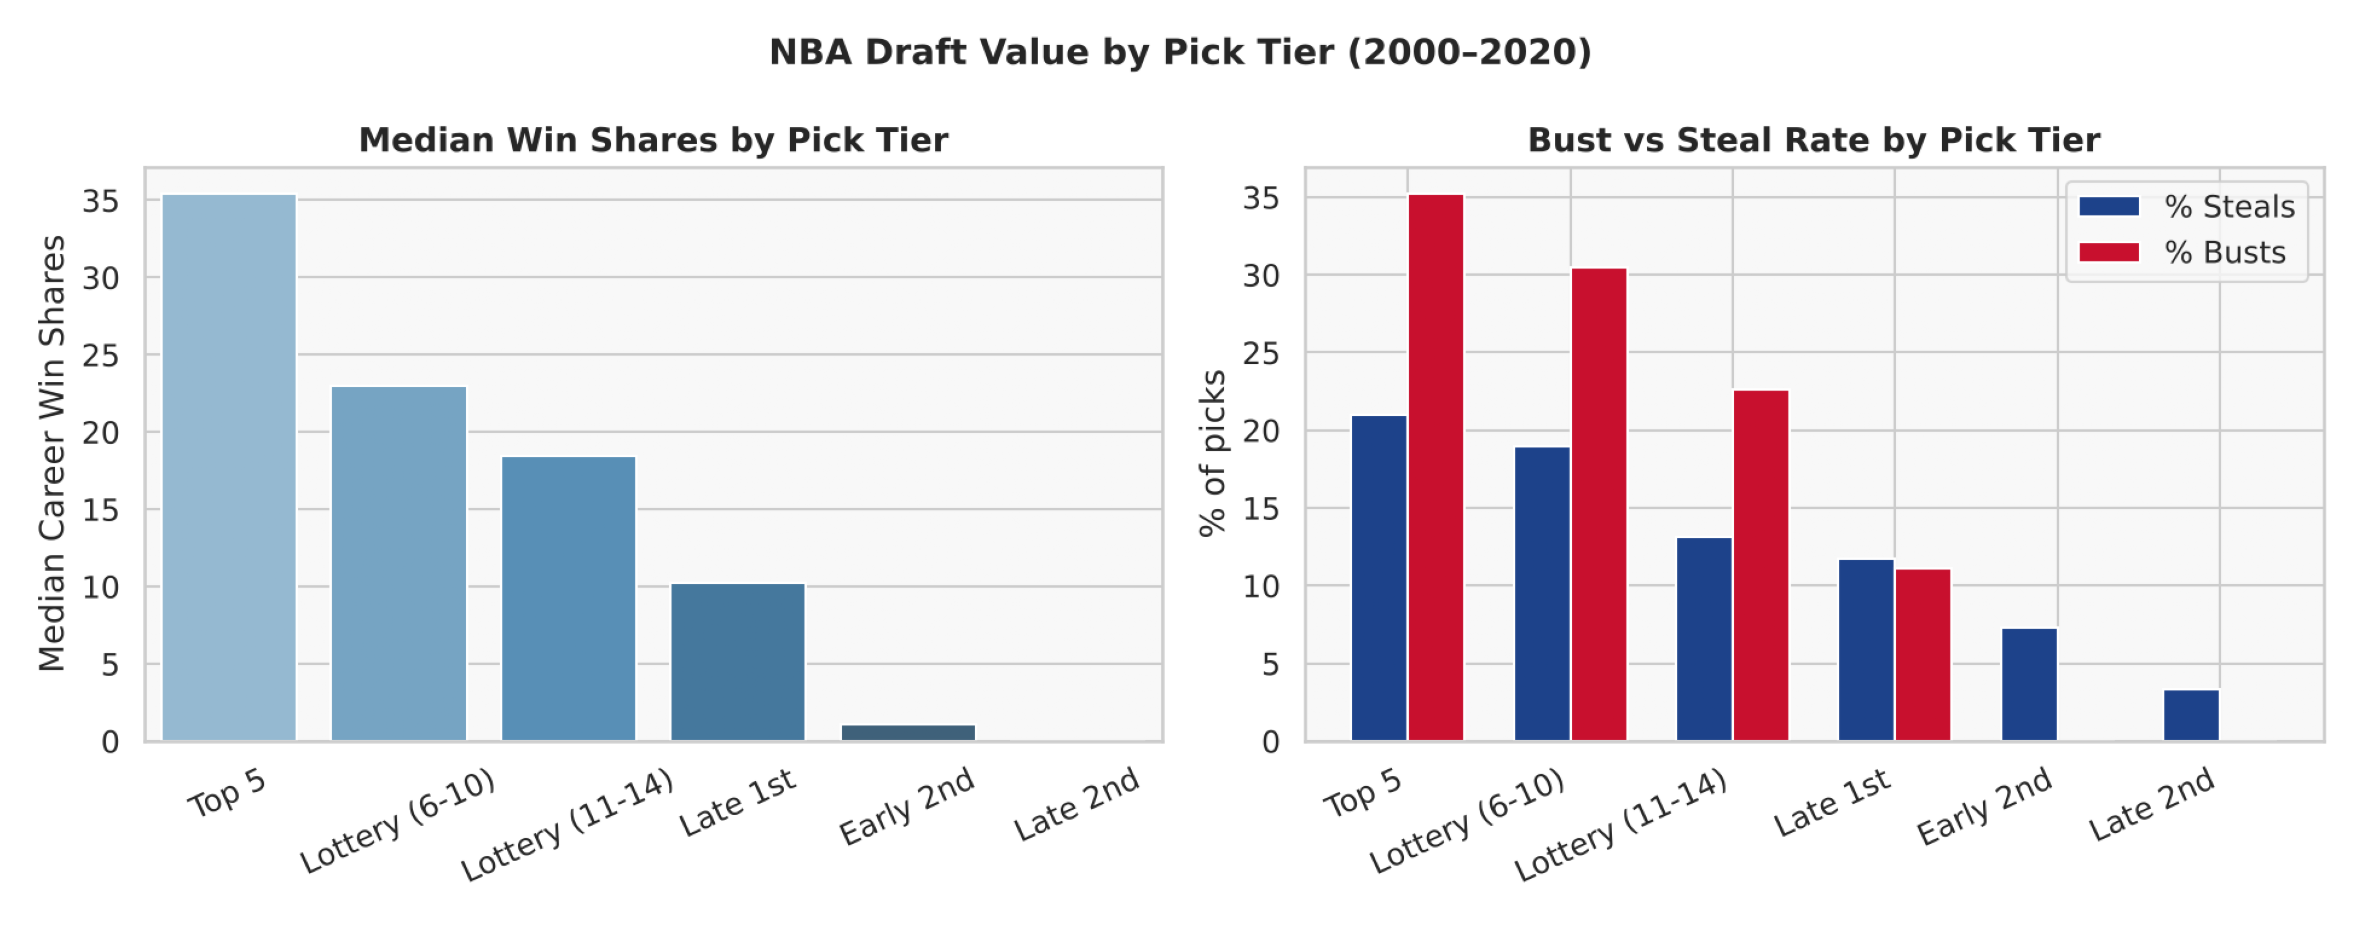

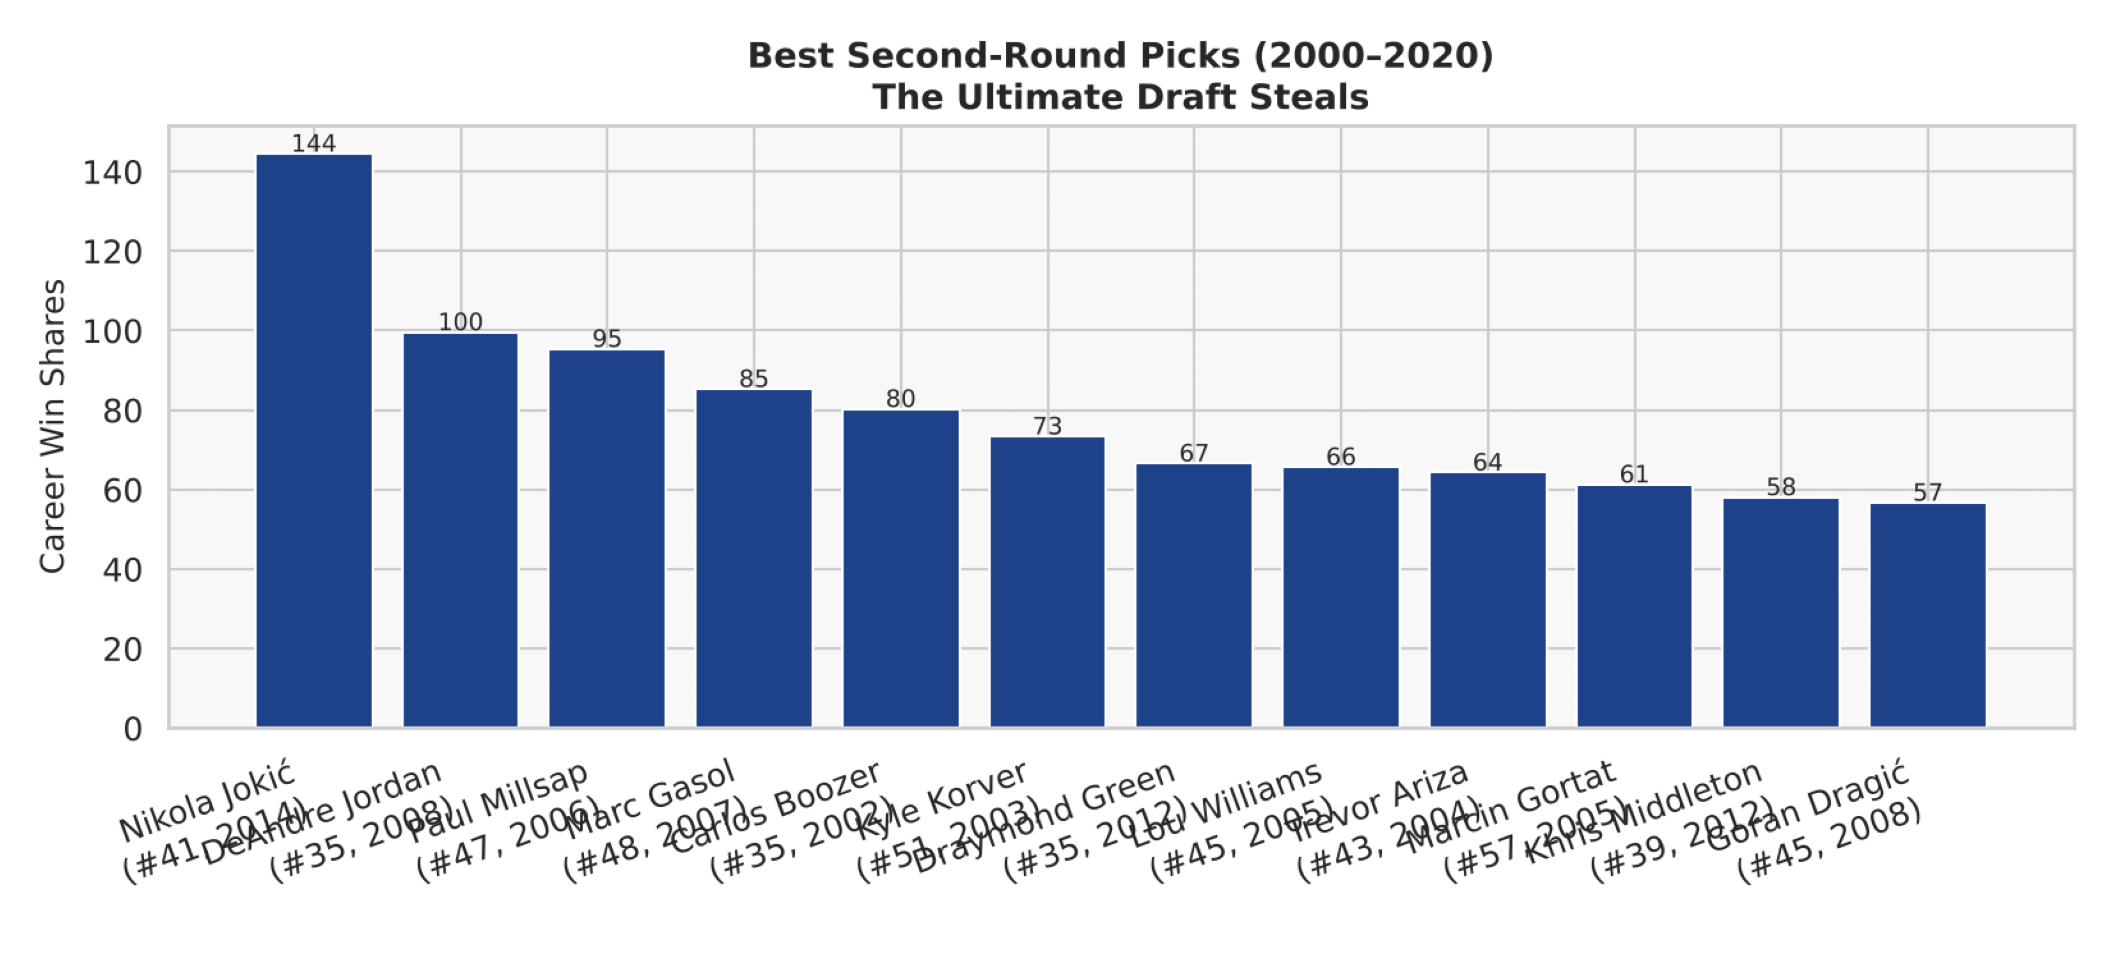

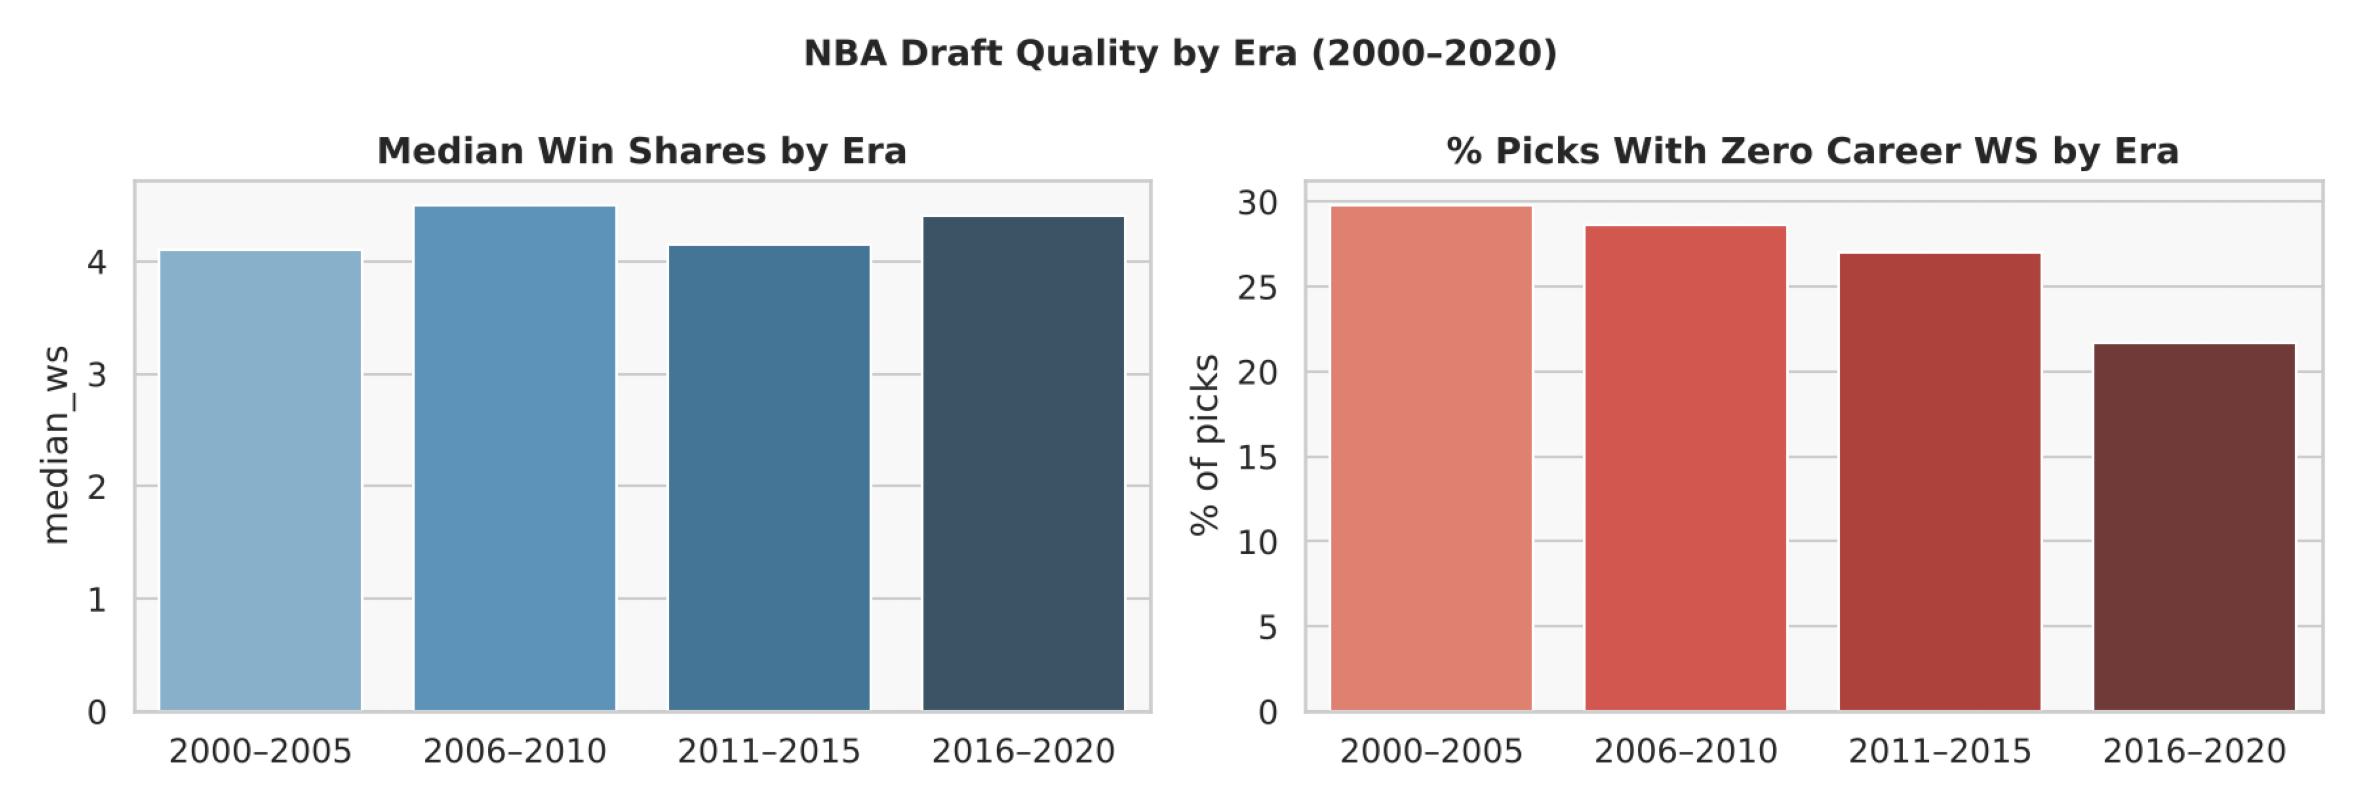

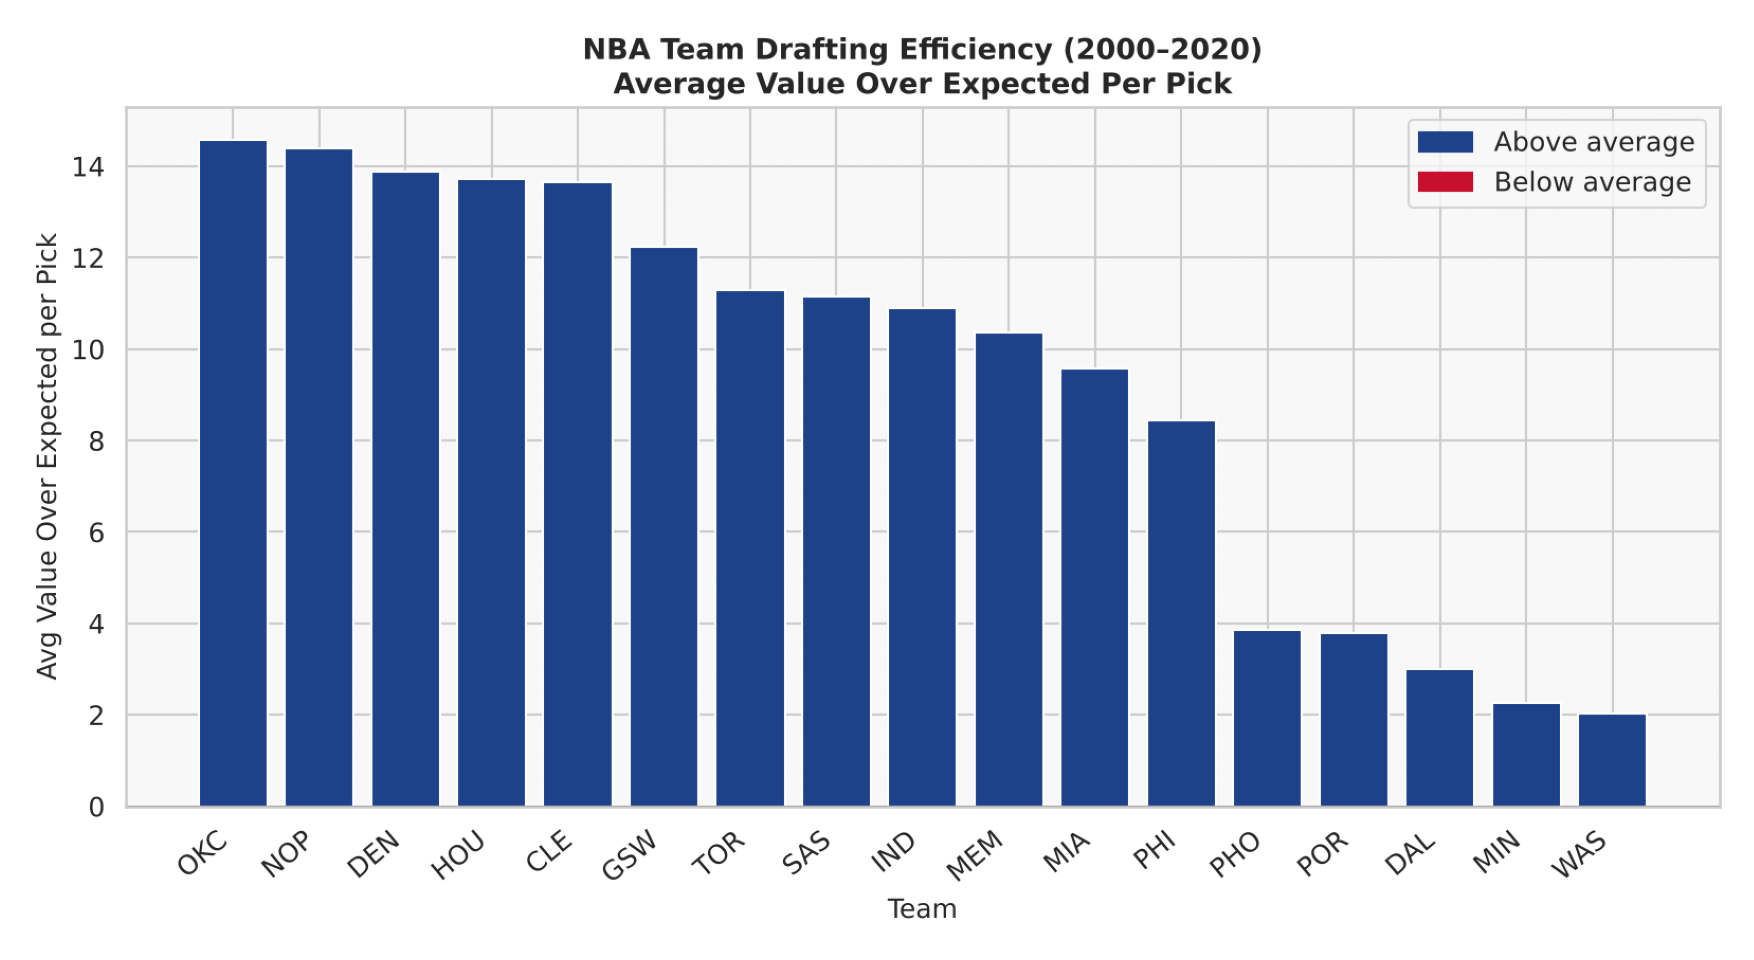

In [13]:
figure_paths = generate_all_figures(results, model_results)

for path in figure_paths:
    img = mpimg.imread(path)
    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

## 11. Key Findings

### Draft Value Curve
- Value drops off steeply with pick number. The median Top 5 pick produced 35.4 career Win Shares, compared with 23.0 for picks 6–10, 10.3 for picks 15–30, and 1.1 for picks 31–45.
- 45% of second-round picks finished with zero or negative career Win Shares, compared with 9% of first-round picks.

### Greatest Steals
- Measured against what their pick slot usually produces, the biggest outperformers were LeBron James (#1, 2003), Chris Paul (#4, 2005), Kevin Durant (#2, 2007), and Nikola Jokić (#41, 2014).
- Jokić is the standout late pick: 144.5 career Win Shares, the most of any second-rounder and 6th-most of anyone drafted 2000–2020. Other late-pick steals include Rudy Gobert (#27), Tony Parker (#28), Jimmy Butler (#30), and Marc Gasol (#48).

### Biggest Busts
- Among picks 1–20, the furthest below expectation were Adam Morrison (#3, 2006), Jahlil Okafor (#3, 2015), and Anthony Bennett (#1, 2013).
- Top 5 picks were flagged as busts most often (35%), partly because high expectations leave the most room to fall short.

### Best Drafting Teams
- Oklahoma City (including its Seattle years) had the highest average value over expected per pick (+14.6), driven by Kevin Durant, Russell Westbrook, and James Harden. New Orleans (+14.4, Chris Paul) and Denver (+13.9, Nikola Jokić) were next.

### Predicting Career Value
- Draft position alone explains only about 20% of the variation in career Win Shares (cross-validated R² = 0.20, mean error 15.5 WS). Adding draft year and round did not improve predictions (R² = 0.12), so most of what makes a career is not captured by where a player was picked.
